In [1]:
import pandas as pd
import math
from sys import float_info
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import shapiro, wilcoxon, ttest_rel, pearsonr
from numpy import std
import numpy as np
#TODO fix Gopstein17b

In [2]:
def lk_to_dict(lk): 
    lk_arr = lk.strip("[]").split("], [")
    dict = {}
    for l in lk_arr: 
        key, val = l.split(", ")
        dict[int(key)] = float(val)
    return(dict)
def loss_from_df(df): 
    correct_labels = df["correct"]
    answer = df["answer"]
    likelihoods = df["likelihoods"]
    eval_loss = 0
    count = 0
    curr_iter = -1
    prob = 1
    losses = []
    tokens = []
    curr_tokens = []
    for label, iter, lk in zip(correct_labels, answer, likelihoods):  
        lbl, atkn = label.strip("[]").split(",")
        lk_dict = lk_to_dict(lk)
        if curr_iter == -1: 
            curr_iter = iter
        if curr_iter == iter : 
            p = lk_dict[int(lbl)] if atkn == " None" else lk_dict[int(lbl)]+lk_dict[int(atkn)] 
            prob *= p
            curr_tokens.append([lbl, atkn])
        else: 
            if prob == 0: 
                    eval_loss += -math.log(float_info.min)
                    losses.append(-math.log(float_info.min))
            else:
                    eval_loss += -math.log(prob)
                    losses.append(-math.log(prob))
            tokens.append(curr_tokens)
            curr_tokens = [[lbl, atkn]]
            count += 1
            p = lk_dict[int(lbl)] if atkn == " None" else lk_dict[int(lbl)]+lk_dict[int(atkn)] 
            prob = p
            curr_iter = iter
    if prob == 0: 
        eval_loss += -math.log(float_info.min)
        losses.append(-math.log(float_info.min))
        count += 1
        tokens.append(curr_tokens)
        curr_tokens = []
    elif prob != 1:
        eval_loss += -math.log(prob)
        losses.append(-math.log(prob))
        count += 1
        tokens.append(curr_tokens)
        curr_tokens = []
    count += 1
    tokens.append(curr_tokens)
    curr_tokens = []
    return(losses, tokens)


In [3]:
def get_values(study, model, variant = "no_order"): 
    answer_amounts = pd.read_csv(f"answer_amounts/{study}.csv")
    result_dict = {"study": [], "model": [], "task": [], "answer": [], "tokens": [], "loss": []}
    amount_sum = 0
    for i in range(len(answer_amounts)):
        task = answer_amounts["task"].iloc[i]
        answer = answer_amounts["answer"].iloc[i]
        amount = answer_amounts["amount"].iloc[i]
        answer_num = answer_amounts["answer_num"].iloc[i]
        if study == "Gopstein17b" and (task == "task_g" or task == "task_h"):
            continue 
        answer_df = pd.read_csv(f"full_results/{model}/{study}_{variant}/{study}_{variant}_{task}_{answer_num}.csv")
        losses, tokens = loss_from_df(answer_df)
        for i in range(amount):
            for loss, token in zip(losses, tokens):
                if study == "Ajami18"and losses== [0.0]: 
                    continue
                result_dict["loss"].append(loss)
                result_dict["task"].append(task)
                result_dict["answer"].append(answer)
                result_dict["tokens"].append(token)
                result_dict["study"].append(study)
                result_dict["model"].append(model)
    return(result_dict)

In [ ]:
studies = ["Ajami18", "Bauer19", "Börstler16", "Buse10", "Gopstein17a", "Gopstein17b", "Medeiros19", "Siegmund17", "Peitek18"]
result_dict = {"study": [], "model": [], "task": [], "answer": [], "tokens": [], "loss": []}
models = ["Centaur", "Llama"]
for study in studies: 
    for model in models: 
        print(study, model)
        data_dict = get_values(study, model)
        for key in result_dict:
            result_dict[key] += data_dict[key]
result_df = pd.DataFrame(result_dict)

Ajami18 Centaur
Ajami18 Llama
Bauer19 Centaur
Bauer19 Llama
Börstler16 Centaur
Börstler16 Llama
Buse10 Centaur
Buse10 Llama
Gopstein17a Centaur
Gopstein17a Llama
Gopstein17b Centaur
Gopstein17b Llama
Medeiros19 Centaur
Medeiros19 Llama
Peitek17 Centaur
Peitek17 Llama
Peitek18b Centaur
Peitek18b Llama


In [5]:
def get_losses(study, df, model): 
    model_data = df[df["model"] == model]
    study_data = model_data[model_data["study"] == study]
    losses = []
    ids = []
    for i in range(len(study_data)):
        losses.append(study_data["loss"].iloc[i])
        ids.append([study_data["task"].iloc[i], study_data["answer"].iloc[i]])
    return losses, ids
def evaluate_study(study, df):
    res_dict = {"study": [], "trials": [], "Centaur_mean":[], "Centaur_std": [], "Llama_mean": [], "Llama_std": [], "tstat": [], "pvalue": [], "cohen_d": []}
    ids_arrs = []
    losses_dict = {"Centaur": [], "Llama": []}
    for model in ["Centaur", "Llama"]: 
        losses, ids = get_losses(study, df, model)
        ids_arrs.append(ids)
        losses_dict[model] = losses
        res_dict[f"{model}_mean"] = np.mean(losses)
        res_dict[f"{model}_std"] = np.std(losses)
    ttest = ttest_rel(losses_dict["Centaur"], losses_dict["Llama"])
    res_dict["tstat"] = ttest.statistic
    res_dict["pvalue"] = ttest.pvalue
    diff = np.array(losses_dict["Centaur"]) - np.array(losses_dict["Llama"])
    cohen_d = ttest.statistic/math.sqrt(len(diff))
    res_dict["cohen_d"] = cohen_d
    if len(ids_arrs[0]) != len(ids_arrs[1]): 
        print("Mismatch, length difference")
    else: 
        res_dict["trials"] = len(losses)
    for id1, id2 in zip(ids_arrs[0], ids_arrs[1]): 
        if id1 != id2: 
            print(f"Mismatch, {id1} and {id2} are unequal")
    res_dict["study"] = study
    return(res_dict)

def eval_all(df):
    res_dict = {"study": [], "trials": [], "Centaur_mean":[], "Centaur_std": [], "Llama_mean": [], "Llama_std": [], "tstat": [], "pvalue": [], "cohen_d": []}
    ids_arrs = []
    losses_dict = {"Centaur": [], "Llama": []}
    for model in ["Centaur", "Llama"]: 
        losses_all = []
        ids_all = []
        for study in studies:
            losses, ids = get_losses(study, df, model)
            losses_all += losses
            ids_all+= ids
        ids_arrs.append(ids_all)
        print(len(losses_all))
        losses_dict[model] = losses_all
        res_dict[f"{model}_mean"] = np.mean(losses_all)
        res_dict[f"{model}_std"] = np.std(losses_all)
    ttest = ttest_rel(losses_dict["Centaur"], losses_dict["Llama"])
    res_dict["tstat"] = ttest.statistic
    res_dict["pvalue"] = ttest.pvalue
    diff = np.array(losses_dict["Centaur"]) - np.array(losses_dict["Llama"])
    cohen_d = ttest.statistic/math.sqrt(len(diff))
    res_dict["cohen_d"] = cohen_d
    if len(ids_arrs[0]) != len(ids_arrs[1]): 
        print("Mismatch, length difference")
    else: 
        res_dict["trials"] = len(losses_all)
    for id1, id2 in zip(ids_arrs[0], ids_arrs[1]): 
        if id1 != id2: 
            print(f"Mismatch, {id1} and {id2} are unequal")
    res_dict["study"] = "overall"
    return(res_dict)

In [6]:
all_res_dict = {"study": [], "trials": [], "Centaur_mean":[], "Centaur_std": [], "Llama_mean": [], "Llama_std": [], "tstat": [], "pvalue": [], "cohen_d": []}
for study in studies: 
    study_res_dict = evaluate_study(study, result_df)
    for key in all_res_dict:
        all_res_dict[key].append(study_res_dict[key])
study_res_dict = eval_all(result_df)
for key in study_res_dict:
    all_res_dict[key].append(study_res_dict[key])
all_res_df = pd.DataFrame(all_res_dict)
all_res_df.to_csv("results/results_RQ2_no_order.csv", index=False)
result_df.to_csv("results/data_RQ2_no_order.csv", index=False)

25554
25554


Ajami18: 2067 Trials
Centaur mean: 0.932397168429738, STD: 1.545742196164567
Llama mean: 1.2615173014216843, STD: 1.7877206351729227
T-test statistic: -11.131501504018992, p-value: 5.4170825975317155e-28, cohen's d: -0.24484064279602108


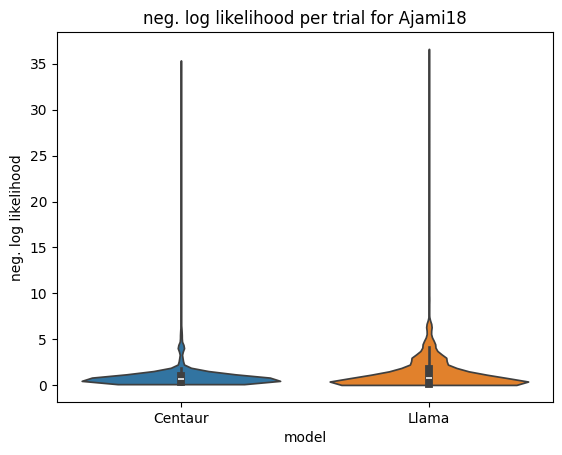

Bauer19: 88 Trials
Centaur mean: 4.337829820081731, STD: 2.786039622519325
Llama mean: 5.15883549324449, STD: 4.026267952635824
T-test statistic: -4.9072946134329225, p-value: 4.269969637352633e-06, cohen's d: -0.5231193634759637


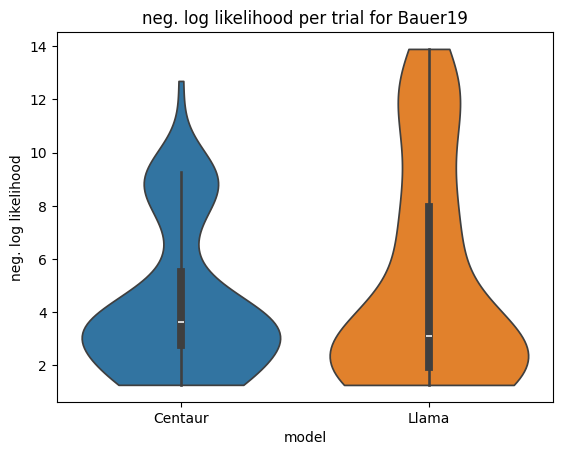

Börstler16: 2598 Trials
Centaur mean: 5.205455582928793, STD: 6.337377043758356
Llama mean: 6.505722704031414, STD: 7.181189307314106
T-test statistic: -21.41190836436393, p-value: 8.387840814199452e-94, cohen's d: -0.42008367316195866


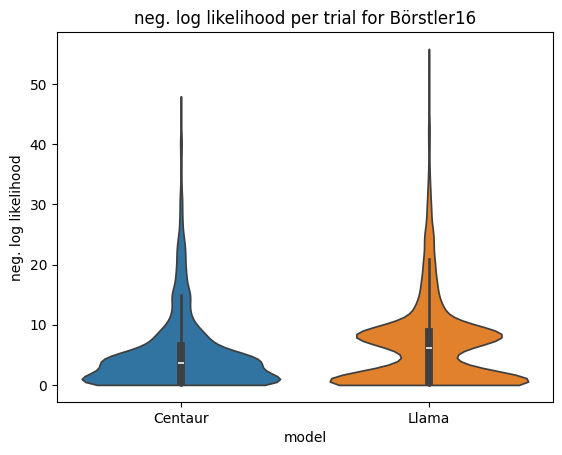

Buse10: 12100 Trials
Centaur mean: 1.5951960428855891, STD: 0.4951125476848587
Llama mean: 2.490051457819082, STD: 1.2866240035091494
T-test statistic: -82.17654678790647, p-value: 0.0, cohen's d: -0.7470595162536953


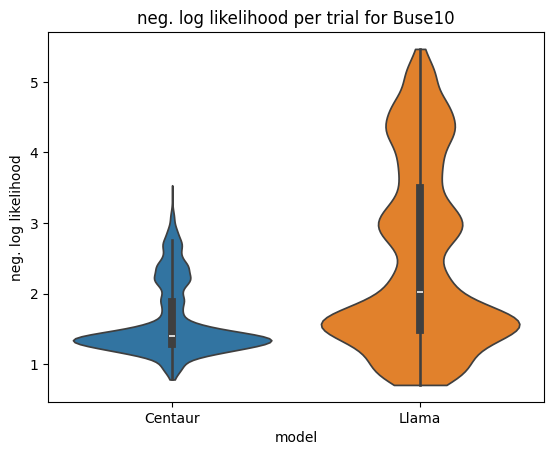

Gopstein17a: 6069 Trials
Centaur mean: 1.636335193979695, STD: 2.97068187913635
Llama mean: 2.0262306713226157, STD: 3.3288002173445284
T-test statistic: -17.286398542705136, p-value: 2.150235564728077e-65, cohen's d: -0.2218942011628028


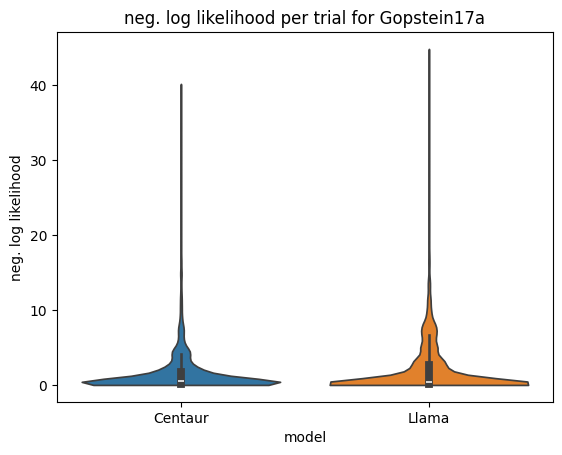

Gopstein17b: 498 Trials
Centaur mean: 4.30044755343099, STD: 3.5013633451525656
Llama mean: 4.3779558915361925, STD: 3.597359259236715
T-test statistic: -0.9887842122965255, p-value: 0.3232498617462545, cohen's d: -0.04430848003017094


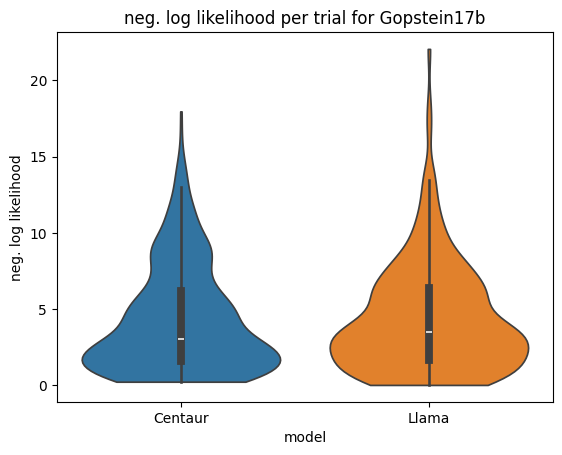

Medeiros19: 1164 Trials
Centaur mean: 1.5693418627415623, STD: 0.37943067303062045
Llama mean: 1.698064199239027, STD: 0.9146817430076953
T-test statistic: -4.199682130543233, p-value: 2.8769876054651618e-05, cohen's d: -0.12309486325093527


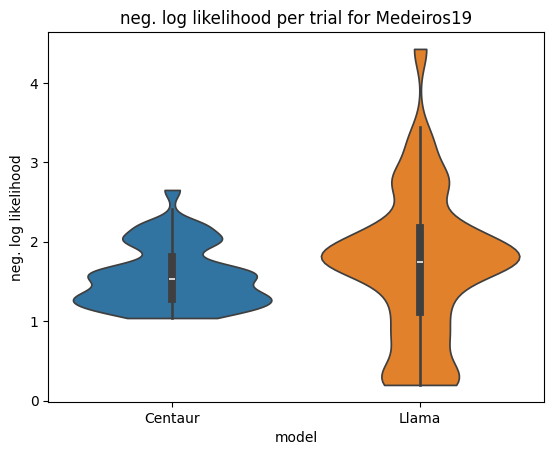

Peitek17: 420 Trials
Centaur mean: 0.7158373882189055, STD: 0.6636638238412296
Llama mean: 1.0992895104980644, STD: 1.6358954216154404
T-test statistic: -6.873967735196986, p-value: 2.2744438225749713e-11, cohen's d: -0.3354152807112301


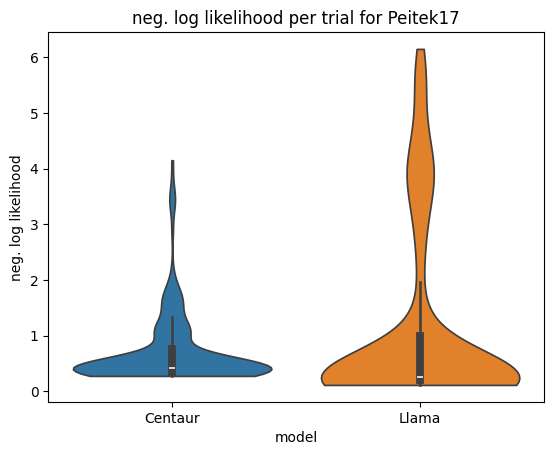

Peitek18b: 550 Trials
Centaur mean: 1.7530312127412568, STD: 0.7499179325755979
Llama mean: 2.8315334628644644, STD: 1.8451978213616487
T-test statistic: -18.877652951980235, p-value: 1.2520277306838733e-61, cohen's d: -0.8049458264949579


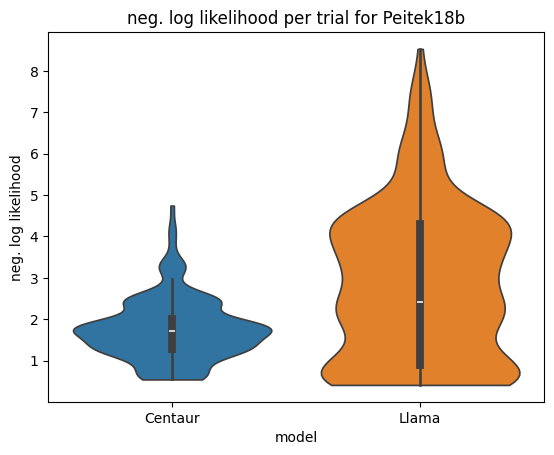

overall: 25554 Trials
Centaur mean: 1.9683303462017023, STD: 2.860700652450506
Llama mean: 2.68318195645572, STD: 3.3634107757872016
T-test statistic: -67.98185758008354, p-value: 0.0, cohen's d: -0.4252688591569216


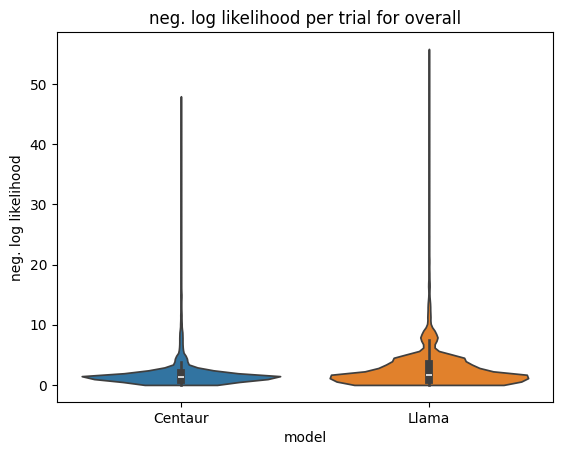

In [7]:
#TODO Violinplots & Eval
import seaborn as sns

import seaborn as sns
variant = "RQ2_no_order"
for study in studies: 
    study_data_df = result_df[result_df["study"]==study]
    study_result_df = all_res_df[all_res_df["study"]==study]
    print(f"{study_result_df['study'].iloc[0]}: {study_result_df['trials'].iloc[0]} Trials") 
    print(f"Centaur mean: {study_result_df['Centaur_mean'].iloc[0]}, STD: {study_result_df['Centaur_std'].iloc[0]}")
    print(f"Llama mean: {study_result_df['Llama_mean'].iloc[0]}, STD: {study_result_df['Llama_std'].iloc[0]}")
    print(f"T-test statistic: {study_result_df['tstat'].iloc[0]}, p-value: {study_result_df['pvalue'].iloc[0]}, cohen's d: {study_result_df['cohen_d'].iloc[0]}")
    sns.violinplot(study_data_df, x = "model", y = "loss", hue = "model", cut=0)
    plt.ylabel("neg. log likelihood")
    plt.title(f"neg. log likelihood per trial for {study}")
    plt.savefig(f"images/{study}_violin_{variant}.png")
    plt.show()
    plt.close()
study = "overall"
study_data_df = result_df
study_result_df = all_res_df[all_res_df["study"]==study]
print(f"{study_result_df['study'].iloc[0]}: {study_result_df['trials'].iloc[0]} Trials") 
print(f"Centaur mean: {study_result_df['Centaur_mean'].iloc[0]}, STD: {study_result_df['Centaur_std'].iloc[0]}")
print(f"Llama mean: {study_result_df['Llama_mean'].iloc[0]}, STD: {study_result_df['Llama_std'].iloc[0]}")
print(f"T-test statistic: {study_result_df['tstat'].iloc[0]}, p-value: {study_result_df['pvalue'].iloc[0]}, cohen's d: {study_result_df['cohen_d'].iloc[0]}")
sns.violinplot(study_data_df, x = "model", y = "loss", hue = "model", cut=0)
plt.ylabel("neg. log likelihood")
plt.title(f"neg. log likelihood per trial for {study}")
plt.savefig(f"images/{study}_violin_{variant}.png")
plt.show()
plt.close()